In [1]:
import numpy as np
import matplotlib.pyplot as plt

import scipy.optimize as opt

In [2]:
# Data
T = np.array([323, 313, 298, 287, 281, 275])
t = np.array([0.125, 5/6, 1, 4, 12, 180])

T_fit = 1/T
t_fit = np.log(1/t)

In [3]:
# fit
def f(x, a, b):
    return a*x + b

popt, pcov = opt.curve_fit(f, T_fit, t_fit)
a, b = popt

In [4]:
## Dependiencies
import matplotlib.pyplot as plt

# params
style:str = 'seaborn-v0_8-bright'
font = {'family' : 'DejaVu Sans',
        'weight' : 'bold',
        'size'   : 16}

class pltStyler():
    style:str
    font:dict[str]
    
    def __init__(self, style:str = style, font:dict[str] = font) -> None:
        self.style = style
        self.font = font
       
    def default_stylesheet(self) -> None:
        plt.style.use('default')
        
    def enforece_stylesheet(self) -> None:
        # just to have a clean slate
        self.default_stylesheet()
        
        # enforce the stylesheet
        plt.style.use(self.style)
        plt.rc('font', **self.font)

In [5]:
np.log(1/0.125)

2.0794415416798357

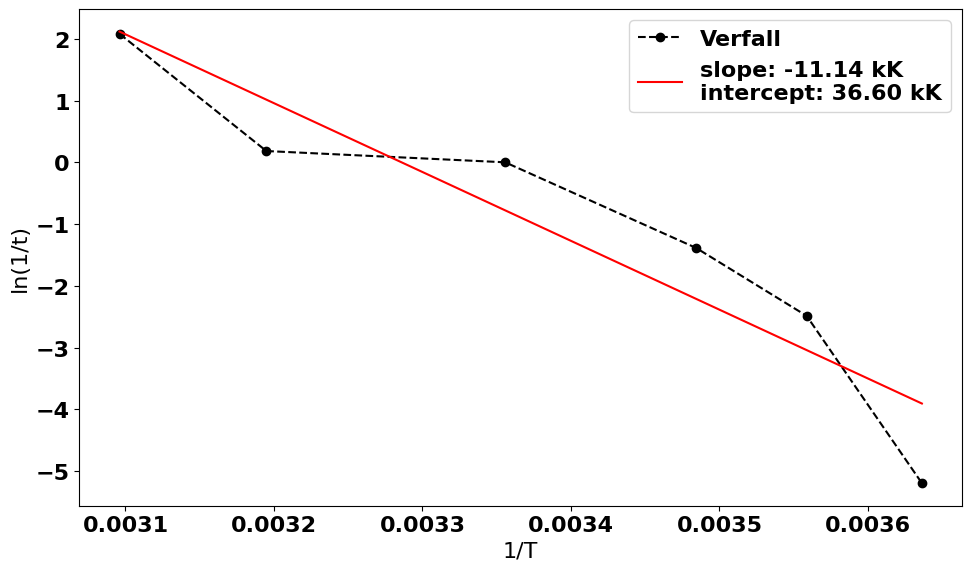

In [11]:
# plot
pltStyler().enforece_stylesheet()

fig, ax = plt.subplots(1,1, figsize=(10, 6), dpi = 100)

# plot
ax.plot(T_fit, t_fit, '--o', label='Verfall', color='black')
ax.plot(T_fit, f(T_fit, *popt), label=f"slope: {popt[0]*1e-3:.2f} kK\nintercept: {popt[1]:.2f} kK", color='red')

# layout
ax.set_xlabel('1/T')
ax.set_ylabel('ln(1/t)')

ax.legend(loc = 'upper right')

fig.tight_layout()
fig.savefig('output.png', dpi = 300, transparent = True)